In [1]:
import pandas as pd
import numpy as np
import math
from PIL import Image

In [2]:
#img = np.asarray(Image.open("chelovechki/1.png").convert("L")) / float(255.0)
#print(img)

In [3]:
df = pd.DataFrame({
    'y' : [0] * 0,
    'et': [0] * 0,
    'er': [0] * 0
})

print(df)



Empty DataFrame
Columns: [y, et, er]
Index: []


In [4]:
def sigma(x):
  res = 0
  if x > 700:
    res = 1
  elif x < -700:
    res = 0
  else: 
    res = 1 / (1 + math.exp(-x))
  return res
def porog(x):
  res = 0
  if x >= 0:
    res = 1
  return res

neironcount = 0

class akson:
  def __init__(self):
    self.wes = 0
  def __repr__(self):
    return str(self.wes)

class neiron:
  def __init__(self):
      global neironcount
      self.aksons = []
      self.neirons = []
      self.id = neironcount
      neironcount += 1
      self.lastvalue = 0
  def getvalue(self):
    f = 0
    for i in range(len(self.neirons)):
      f += self.aksons[i].wes * self.neirons[i].getvalue()
    res = sigma(f)
    self.lastvalue = res
    return res

class inputneiron(neiron):
  def setvalue(self, x):
    self.myvalue = x
  def getvalue(self):
    #print(f"в нейроне {self.id} значение {self.myvalue} x")
    self.lastvalue = self.myvalue
    return self.myvalue
  def __init__(self):
    super().__init__()
    self.myvalue = 0

class outputneiron(neiron):
  def getvalue(self):
    f = 0
    for i in range(len(self.aksons)):
      f += self.aksons[i].wes * self.neirons[i].getvalue()
    res = porog(f)
    self.lastvalue = res
    return res

In [5]:
import random

layer1 = [inputneiron() for i in range(36)]
layer2 = [neiron() for i in range(6)]
layer3 = outputneiron()
biasneiron = inputneiron()
biasneiron.setvalue(1)
neironsall = layer1 + layer2 + [layer3]
aksonsall = []

layer1.append(biasneiron)
layer2.append(biasneiron)
layer3.neirons.append(biasneiron)

for n in layer2:
  n.neirons = layer1
  for j in range(len(layer1)):
    n.aksons.append(akson())

layer3.neirons = layer2
for j in range(len(layer2)):
  layer3.aksons.append(akson())

for n in neironsall:
  for a in n.aksons:
    a.wes = random.uniform(-1, 1)
    aksonsall.append(a)

for a in aksonsall:
  a.wes = random.uniform(-1, 1)

In [6]:
def showwesa():
  for a in aksonsall:
    print(a.wes)
#print(aksonsall)
#showwesa()
print(aksonsall)

[-0.10274654486468293, 0.694628407431781, -0.5320609758915333, -0.14831437415603466, 0.5036718713946708, 0.7836424365012833, 0.36056464668532184, -0.406293194778776, -0.06416492569713239, -0.6531228015180865, 0.8752906563772376, -0.9243791464728142, -0.7221608200279981, -0.25737357325493937, 0.1608556512279986, -0.30849803565843104, 0.562573660333126, 0.5327003771195782, -0.6002441097031666, 0.6460602260490056, 0.13186186264510846, -0.8497582804034303, -0.1119389979374723, -0.5212803253838656, 0.013694410380648225, -0.6890457918218944, 0.2298949826511234, 0.8769247054286993, -0.4775971159312644, 0.6916464662674973, 0.2435342665825797, 0.9991037136266689, 0.5105617964175788, -0.3432829639706716, -0.6768734215718326, -0.9008859197470627, 0.5086951050932906, -0.31804704927461813, -0.8504936763911648, 0.03793747140505199, -0.7544662737558014, 0.4564426050647652, -0.5430686326683856, -0.6393693390081017, -0.9775912725333098, -0.42950574862560176, -0.5107155746037537, 0.18049204810680708, -0

Теперь надо разобраться с загрузкой датасета и использованием изображений из папки chelovechki

In [7]:
import requests
import os
'''
## Set the GitHub repository and folder details
repo_url = "https://api.github.com/repos/ashotnafig1/Neironki/contents/Lab02/chelovechki"
local_path = "chelovechki"

os.makedirs(local_path, exist_ok=True)
## Send a GET request to the GitHub API
response = requests.get(repo_url)

## Iterate through the folder contents and download each file
for item in response.json():
    if item["type"] == "file":
        file_url = item["download_url"]
        file_name = item["name"]
        file_path = f"{local_path}/{file_name}"

        ## Download the file
        file_response = requests.get(file_url)
        with open(file_path, "wb") as file:
            file.write(file_response.content)
'''

'\n## Set the GitHub repository and folder details\nrepo_url = "https://api.github.com/repos/ashotnafig1/Neironki/contents/Lab02/chelovechki"\nlocal_path = "chelovechki"\n\nos.makedirs(local_path, exist_ok=True)\n## Send a GET request to the GitHub API\nresponse = requests.get(repo_url)\n\n## Iterate through the folder contents and download each file\nfor item in response.json():\n    if item["type"] == "file":\n        file_url = item["download_url"]\n        file_name = item["name"]\n        file_path = f"{local_path}/{file_name}"\n\n        ## Download the file\n        file_response = requests.get(file_url)\n        with open(file_path, "wb") as file:\n            file.write(file_response.content)\n'

In [8]:
# возвращает np массив изображения, причём нормализованный
def readimage(path):
    return np.asarray(Image.open(path).convert("L")) / float(255.0) 

table = pd.read_csv("chelovechki/tablica.txt", sep=' ')
table["y"] = None
table["err"] = None

print(table)

def getimage(number):
    return readimage("chelovechki/" + str(number) + ".png").flatten()
for i in range(len(table)):
    print(getimage(i))

    id  class     y   err
0    0      1  None  None
1    1      1  None  None
2    2      1  None  None
3    3      0  None  None
4    4      1  None  None
5    5      1  None  None
6    6      0  None  None
7    7      1  None  None
8    8      1  None  None
9    9      0  None  None
10  10      1  None  None
11  11      1  None  None
12  12      0  None  None
13  13      1  None  None
14  14      1  None  None
15  15      0  None  None
16  16      1  None  None
17  17      0  None  None
18  18      1  None  None
19  19      0  None  None
20  20      0  None  None
21  21      0  None  None
22  22      0  None  None
23  23      1  None  None
24  24      1  None  None
25  25      1  None  None
26  26      0  None  None
27  27      0  None  None
28  28      1  None  None
29  29      0  None  None
30  30      1  None  None
31  31      0  None  None
32  32      1  None  None
33  33      0  None  None
34  34      0  None  None
35  35      0  None  None
36  36      0  None  None
37  37      

In [9]:
#
def Test(X):
  for i in range(len(X)):
    layer1[i].setvalue(X[i])
  return layer3.getvalue()


In [10]:
def bigtest():
  s = 0
  sq = 0
  for i, clas in table.iterrows():
    X = getimage(i)
    y_pred = Test(X)
    table.loc[i, "y"]  = y_pred
    table.loc[i, "err"] = table.loc[i, "class"] - y_pred
    s += table.loc[i, "err"]
    sq += (table.loc[i, "err"])**2
  return float(s), float(sq)

summa, summaq = bigtest()
print(summa, summaq)
print(table)

-24.0 24.0
    id  class  y err
0    0      1  1   0
1    1      1  1   0
2    2      1  1   0
3    3      0  1  -1
4    4      1  1   0
5    5      1  1   0
6    6      0  1  -1
7    7      1  1   0
8    8      1  1   0
9    9      0  1  -1
10  10      1  1   0
11  11      1  1   0
12  12      0  1  -1
13  13      1  1   0
14  14      1  1   0
15  15      0  1  -1
16  16      1  1   0
17  17      0  1  -1
18  18      1  1   0
19  19      0  1  -1
20  20      0  1  -1
21  21      0  1  -1
22  22      0  1  -1
23  23      1  1   0
24  24      1  1   0
25  25      1  1   0
26  26      0  1  -1
27  27      0  1  -1
28  28      1  1   0
29  29      0  1  -1
30  30      1  1   0
31  31      0  1  -1
32  32      1  1   0
33  33      0  1  -1
34  34      0  1  -1
35  35      0  1  -1
36  36      0  1  -1
37  37      1  1   0
38  38      0  1  -1
39  39      0  1  -1
40  40      0  1  -1
41  41      0  1  -1
42  42      1  1   0
43  43      1  1   0
44  44      0  1  -1
45  45      0  1  -1
46

Всё готово, можно пробовать делать обучение


In [11]:
param = 0.35


#showwesa()

In [12]:

#def korrektirowka():
#  for i, row in df.iterrows():


In [13]:
# это пайтон версия обучения с корректировкой
'''
epohi = 0
while (summaq != 0) and (epohi < 1000):
  correctwesa()
  summa, summaq = bigtest()
  epohi += 1

print(aksonsall)
print("эпох: " + str(epohi))
print(table)
'''

'\nepohi = 0\nwhile (summaq != 0) and (epohi < 1000):\n  correctwesa()\n  summa, summaq = bigtest()\n  epohi += 1\n\nprint(aksonsall)\nprint("эпох: " + str(epohi))\nprint(table)\n'

In [14]:
# neir это испытуемый нейрон
# i это локальный индекс испытуемого веса (и нейрона на другой стороне тоже)
# BIGerror это квадратичная ошибка
# чтобы не вычислять каждый раз ошибку внутри функции
# её лучше в параметр передавать
# и не важно, что всё равно вычислять придётся, может быть и нет
def getdldw(neir, i, BIGerror):
    y = neir.lastvalue
    x = neir.neirons[i].lastvalue
    res = BIGerror * y * (1 - y) * x
    return res

def getBIGerror():
    s = 0
    sq = 0
    for i, clas in table.iterrows():
        X = getimage(i)
        y_pred = Test(X)
        table.loc[i, "y"]  = y_pred
        table.loc[i, "err"] = table.loc[i, "class"] - y_pred
        s += table.loc[i, "err"]
        sq += (table.loc[i, "err"])**2
    return float(s), float(sq)
    

In [15]:
# опять поставлю на выходной нейрон сигмоиду чтобы красиво работало
def getvaluePOROG(self):
    f = 0
    for i in range(len(self.aksons)):
      f += self.aksons[i].wes * self.neirons[i].getvalue()
    res = porog(f)
    self.lastvalue = res
    return res

def getvalueSIGMO(self):
    f = 0
    for i in range(len(self.neirons)):
      f += self.aksons[i].wes * self.neirons[i].getvalue()
    res = sigma(f)
    self.lastvalue = res
    return res

outputneiron.getvalue = getvalueSIGMO


всё что выше была заготовка самих данных, алгоритма обучения и способов как это связать.
Пора проверять чё я там настрочил

In [16]:
maloe = 10e-4
speed = 0.1

epohi = 0
bigerrors = []
BIG, BIGQ = getBIGerror()
while BIGQ > maloe and epohi < 2000:
    for i, clas in table.iterrows():
        X = getimage(i)
        y = Test(X)
        e = table.loc[i, "class"]
        for n in neironsall:
            for j in range(len(n.neirons)):
                n.aksons[j].wes += getdldw(n, j, e - y) * speed
    BIG, BIGQ = getBIGerror()
    bigerrors.append(BIGQ)
    epohi += 1
bigerrors.append(BIGQ)

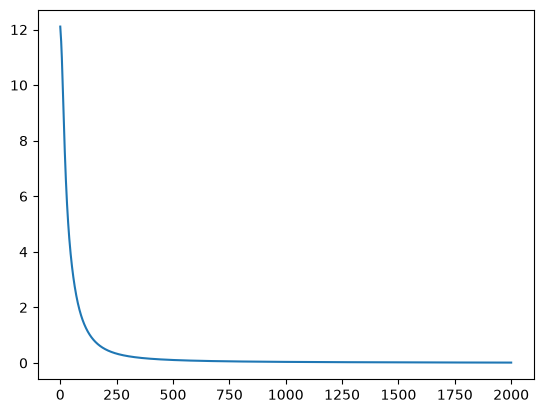

In [17]:
from matplotlib import pyplot as plt
plt.plot(np.arange(0, epohi + 1), bigerrors)

In [18]:
print(table)
#showwesa()
print(aksonsall)
with open("wesaBACKPRO.txt", "w") as file:
    for a in aksonsall:
        file.write(str(a) + '\n')


    id  class         y       err
0    0      1  0.993735  0.006265
1    1      1  0.999262  0.000738
2    2      1  0.971169  0.028831
3    3      0  0.038848 -0.038848
4    4      1  0.998956  0.001044
5    5      1  0.998919  0.001081
6    6      0  0.002269 -0.002269
7    7      1  0.995433  0.004567
8    8      1  0.996035  0.003965
9    9      0   0.01942  -0.01942
10  10      1  0.986988  0.013012
11  11      1  0.986243  0.013757
12  12      0  0.003106 -0.003106
13  13      1  0.999294  0.000706
14  14      1  0.974652  0.025348
15  15      0  0.020998 -0.020998
16  16      1    0.9982    0.0018
17  17      0  0.016195 -0.016195
18  18      1  0.996396  0.003604
19  19      0  0.009399 -0.009399
20  20      0  0.031721 -0.031721
21  21      0  0.003419 -0.003419
22  22      0  0.006828 -0.006828
23  23      1  0.999386  0.000614
24  24      1  0.992591  0.007409
25  25      1   0.99894   0.00106
26  26      0    0.0148   -0.0148
27  27      0  0.004706 -0.004706
28  28      1 

In [19]:
outputneiron.getvalue = getvaluePOROG
getBIGerror()
print(table)
showwesa()

    id  class  y err
0    0      1  1   0
1    1      1  1   0
2    2      1  1   0
3    3      0  0   0
4    4      1  1   0
5    5      1  1   0
6    6      0  0   0
7    7      1  1   0
8    8      1  1   0
9    9      0  0   0
10  10      1  1   0
11  11      1  1   0
12  12      0  0   0
13  13      1  1   0
14  14      1  1   0
15  15      0  0   0
16  16      1  1   0
17  17      0  0   0
18  18      1  1   0
19  19      0  0   0
20  20      0  0   0
21  21      0  0   0
22  22      0  0   0
23  23      1  1   0
24  24      1  1   0
25  25      1  1   0
26  26      0  0   0
27  27      0  0   0
28  28      1  1   0
29  29      0  0   0
30  30      1  1   0
31  31      0  0   0
32  32      1  1   0
33  33      0  0   0
34  34      0  0   0
35  35      0  0   0
36  36      0  0   0
37  37      1  1   0
38  38      0  0   0
39  39      0  0   0
40  40      0  0   0
41  41      0  0   0
42  42      1  1   0
43  43      1  1   0
44  44      0  0   0
45  45      0  0   0
46  46      1

In [20]:
print(len(aksonsall))
print("это столько весов")

229
это столько весов


Теперь метод коррекции будет

In [21]:
for a in aksonsall:
    a.wes = random.uniform(-1, 1)

def correctwesa(eror):
    for n in neironsall:
        for a in n.aksons:
            a.wes -= eror * n.getvalue() * param * random.choice((-1, 1))


outputneiron.getvalue = getvalueSIGMO
summa, summaq = bigtest()
print(summa, summaq)
print(table)


4.673018385149037 12.259524800051626
    id  class         y       err
0    0      1  0.423809  0.576191
1    1      1  0.413667  0.586333
2    2      1  0.354675  0.645325
3    3      0   0.39477  -0.39477
4    4      1  0.413382  0.586618
5    5      1  0.392945  0.607055
6    6      0  0.432784 -0.432784
7    7      1  0.408054  0.591946
8    8      1  0.385198  0.614802
9    9      0  0.392812 -0.392812
10  10      1  0.420694  0.579306
11  11      1  0.400426  0.599574
12  12      0  0.418343 -0.418343
13  13      1  0.336155  0.663845
14  14      1  0.387113  0.612887
15  15      0  0.425871 -0.425871
16  16      1  0.361196  0.638804
17  17      0  0.345097 -0.345097
18  18      1  0.370387  0.629613
19  19      0  0.355864 -0.355864
20  20      0  0.405606 -0.405606
21  21      0  0.444568 -0.444568
22  22      0  0.397169 -0.397169
23  23      1  0.420032  0.579968
24  24      1  0.372063  0.627937
25  25      1  0.382149  0.617851
26  26      0  0.382616 -0.382616
27  27     

In [22]:
# обучение с корректировкой и случайным знаком (фигня полная)
epohi2 = 0
bigerrors2 = []
summaq = 1
while (summaq > maloe) and (epohi2 < 2000):
    for i, clas in table.iterrows():
          X = getimage(i)
          y = Test(X)
          e = table.loc[i, "class"]
          correctwesa(e - y)
    summa, summaq = getBIGerror()
    bigerrors2.append(summaq)
    epohi2 += 1
bigerrors2.append(summaq)
print(aksonsall)
print("эпох: " + str(epohi2))
print(table)

[-63.303791906485074, -70.82395012395806, 72.91781373413752, -89.61737341838395, -5.997941424262947, 16.235638764122147, 75.70925274235762, 7.986514370670644, 32.03224483412851, 86.52631099500367, -120.62339603897043, 17.43868767253554, 0.6606764377100678, 78.1704975677891, 5.990014576113932, 22.40612362956246, 68.18813287840064, 6.711679522834698, 25.938875070056643, -62.5027989967079, 31.013812277350787, -29.625742186032145, -36.65691612209927, 10.558047549047664, -58.53282116887747, -44.450622490114455, -27.623044609654713, 63.924566211360776, 60.12654615328182, -14.84946456278949, 22.296004487919724, -52.62093379839672, -150.25691056644678, 44.9129220218663, -18.01430443303735, 42.2869775450668, -34.10108383639296, -18.14084624059973, -41.64124699848152, -33.33854024679337, -100.30766328111865, 2.8595617882563578, 55.21229920289743, 18.29345192042665, 47.45020117593903, -4.113532033998458, 124.97141634948606, 7.696396751674838, -22.873094322299306, -42.2924451832333, -104.646682737

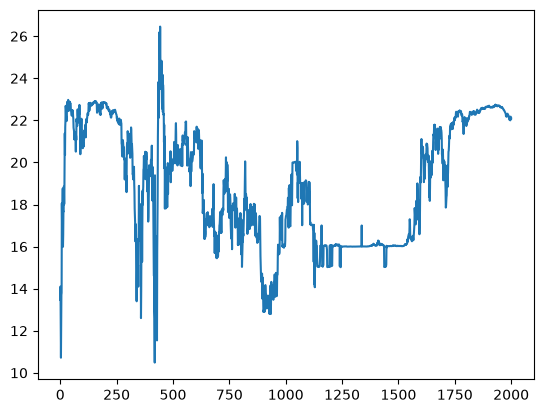

In [23]:
plt.plot(np.arange(0, epohi2 + 1), bigerrors2)

обучение с рандомным подкреплением уже обречено на провал, а метод коррекции корректен только для выходного слоя

для GUI верну веса полученные бекпропом

In [24]:

with open("wesaBACKPRO.txt", "r") as file:
    line = file.readline()
    i = 0
    while line:
        aksonsall[i].wes = float(line)
        i += 1
        line = file.readline()

In [25]:
outputneiron.getvalue = getvaluePOROG

In [26]:
# ИНТЕРФЭЭЭЙС
%gui qt6

import sys
from PyQt6 import QtWidgets as qw

allbuttons = []
class krutayaknopka(qw.QPushButton):
    def __init__(self, text, myvalue, parent = ...):
        super().__init__()
        self.myvalue = myvalue
        self.activated = 1
        self.selectcolor()
        self.clicked.connect(self.selectcolor)
    def selectcolor(self):
        if self.activated == 0:
            self.activated = 1
            self.setStyleSheet("background-color: #FFFFFF")
        else:
            self.activated = 0
            self.setStyleSheet("background-color: #000000")
        self.delegat()
    def delegat(self):
        return

class krutoeokno(qw.QMainWindow):
    def __init__(self):
        super().__init__()
        razmer = 6

        layout = qw.QHBoxLayout()
        self.label = qw.QLabel("sadsadsad")
        layout.addWidget(self.label)
        grid = qw.QGridLayout()
        gridwidget = qw.QWidget()
        gridwidget.setFixedSize(50 * razmer, 50 * razmer)
        gridwidget.setLayout(grid)
        layout.addWidget(gridwidget)

        for row in range(razmer):
            for col in range(razmer):
                b = krutayaknopka("", row * razmer + col)
                b.setFixedSize(50, 50)
                allbuttons.append(b)
                grid.addWidget(b, row, col)
                
        
        self.setWindowTitle("акошко")
        self.setGeometry(100, 50, 800, 500)
        container = qw.QWidget()
        container.setLayout(layout)
        self.setCentralWidget(container)
        
window = krutoeokno()

def predictevent(kacherishka):
    X = [float(b.activated) for b in allbuttons]
    y = Test(X)
    if y == 0:
        window.label.setText("стоит")
    else:
        window.label.setText("идёт")
krutayaknopka.delegat = predictevent

window.show()